# Supplementary figure: validation of all lung DEGs in the spatial data

Unfiltered version of Fig. 3c: log fold changes (fast vs slow progression) in the GeoMx data of all lung single-cell DEGs that are measured in the spatial data,
per region and emphysema status (E: emphysema, N: no emphysema). The processing is identical to Fig. 3c (genes with a consistent direction across cell types,
Benjamini-Hochberg correction per region, non-significant or discordant log fold changes set to 0, ribosomal genes removed), but genes are not
restricted to those with at least one region at $p_{adj}$ < 0.05.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.multitest import multipletests

from figure_style import DENSE_FONT_SIZE, FONT_SIZE, SMALL_FONT_SIZE, figure_size, save_panel, set_style

set_style()
DATA = Path("../data")

In [2]:
lung_markers = pd.read_csv(DATA / "6_lung_deg_results.csv", index_col=0)
spatial_df = pd.read_csv(DATA / "8_GeoMx_DEG_results.csv")
spatial_df.columns = spatial_df.columns.str.replace("paremchyma", "parenchyma")

significant_hits = lung_markers[lung_markers["significant"]]
spatial_hits = spatial_df[spatial_df["Gene"].isin(significant_hits["gene"].unique())].set_index("Gene")

# Exclude genes with diverse dynamics in different cell types
repeating_genes = significant_hits.groupby("gene").describe()["logFC"]
repeating_genes = repeating_genes[repeating_genes["count"] > 1]
diverse_dynamics_genes = repeating_genes[repeating_genes["min"] * repeating_genes["max"] < 0]
significant_hits = significant_hits[~significant_hits["gene"].isin(diverse_dynamics_genes.index)]

In [3]:
regions = [
    "FASTvsSLOW | E_airway", "FASTvsSLOW | E_lymphoid follicle", "FASTvsSLOW | E_parenchyma", "FASTvsSLOW | E_vessel",
    "FASTvsSLOW | NOE_airway", "FASTvsSLOW | NOE_lymphoid follicle", "FASTvsSLOW | NOE_parenchyma", "FASTvsSLOW | NOE_vessel",
]
readable_group_names = {
    "LFC_FASTvsSLOW | E_airway": "E_airway", "LFC_FASTvsSLOW | E_lymphoid follicle": "E_lymphoid follicle",
    "LFC_FASTvsSLOW | E_parenchyma": "E_parenchyma", "LFC_FASTvsSLOW | E_vessel": "E_ vessel",
    "LFC_FASTvsSLOW | NOE_airway": "N_airway", "LFC_FASTvsSLOW | NOE_lymphoid follicle": "N_lymphoid follicle",
    "LFC_FASTvsSLOW | NOE_parenchyma": "N_parenchyma", "LFC_FASTvsSLOW | NOE_vessel": "N_vessel",
}

for region in regions:
    spatial_hits[f"PVAL_adj_{region}"] = multipletests(spatial_hits[f"PVAL_{region}"], method="fdr_bh")[1]

# Zero-out logFCs which are not statistically significant or have a different direction in spatial and single-cell data
for region in regions:
    spatial_hits.loc[spatial_hits[f"PVAL_adj_{region}"] > 0.1, f"LFC_{region}"] = 0
    for gene, logfc in spatial_hits.loc[spatial_hits[f"PVAL_adj_{region}"] < 0.1, f"LFC_{region}"].items():
        sc_progression_coef = significant_hits.loc[significant_hits["gene"] == gene, "logFC"].mean()
        if not (sc_progression_coef * logfc) > 0:
            spatial_hits.loc[gene, f"LFC_{region}"] = 0
            spatial_hits.loc[gene, f"PVAL_adj_{region}"] = 1

# Remove ribosomal genes as many of them had diverging dynamics between SC and spatial data
selected_genes = spatial_hits.index[spatial_hits[[f"LFC_{region}" for region in regions]].abs().sum(axis=1) > 0]
selected_genes = selected_genes[~selected_genes.str.startswith("RPS") & ~selected_genes.str.startswith("RPL")]
len(selected_genes)

58

In [4]:
def pval_to_asterisk(pval):
    if pval < 0.001:
        return "∗∗∗"
    elif pval < 0.01:
        return "∗∗"
    elif pval < 0.05:
        return "∗"
    elif pval < 0.1:
        return "·"
    return ""


pvals_annotation = spatial_hits.loc[selected_genes, [f"PVAL_adj_{region}" for region in regions]].map(pval_to_asterisk)
pvals_annotation.columns = [f"LFC_{region}" for region in regions]

gene_order = spatial_hits.loc[selected_genes, [f"LFC_{region}" for region in regions]].mean(axis=1).sort_values().index
displayed_hits = spatial_hits.loc[gene_order, [f"LFC_{region}" for region in regions]]
displayed_hits = displayed_hits.loc[:, displayed_hits.sum() != 0]  # Drop regions with no DEGs
displayed_annotation = pvals_annotation.loc[gene_order, displayed_hits.columns]
displayed_hits = displayed_hits.rename(columns=readable_group_names)
displayed_hits.shape

(58, 6)

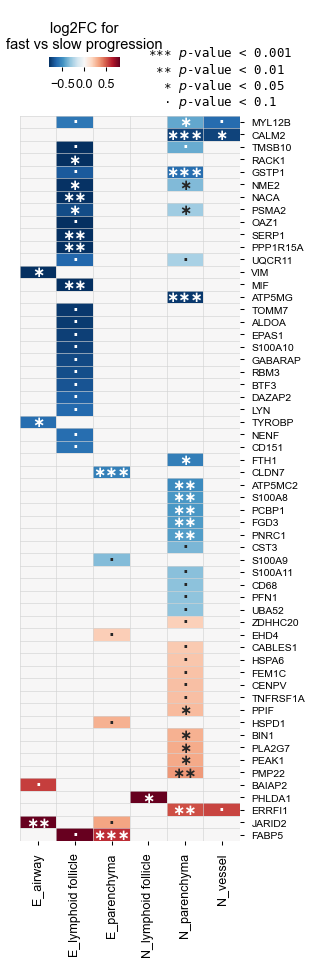

In [5]:
g = sns.clustermap(
    displayed_hits, yticklabels=True, cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8, figsize=figure_size(60, 165),
    annot=displayed_annotation, col_cluster=False, row_cluster=False, fmt="", dendrogram_ratio=(0.02, 0.12),
    annot_kws={"size": FONT_SIZE, "weight": "bold", "family": "DejaVu Sans"}, cbar_kws={"label": "log2FC for\nfast vs slow progression", "orientation": "horizontal"},
)
g.ax_heatmap.set_ylabel("")
g.ax_heatmap.tick_params(axis="y", labelsize=DENSE_FONT_SIZE)  # Gene names
g.ax_cbar.set_position([0.14, 0.93, 0.2, 0.01])
g.ax_cbar.tick_params(labelsize=SMALL_FONT_SIZE)
g.ax_cbar.xaxis.label.set_va("center")
g.ax_cbar.xaxis.label.set_ha("center")
g.ax_cbar.xaxis.label.set_rotation(0)
g.ax_cbar.xaxis.set_label_position("top")

p_value_labels = ["∗∗∗ $p$-value < 0.001", " ∗∗ $p$-value < 0.01", "  ∗ $p$-value < 0.05", "  · $p$-value < 0.1"]
for i, label in enumerate(p_value_labels):
    g.ax_heatmap.text(x=3.5, y=-5 + i * 1.3, s=label, ha="left", va="center", fontsize=SMALL_FONT_SIZE, fontdict={"family": "monospace"})

# Grid between the cells
g.ax_heatmap.set_xticks(np.arange(displayed_hits.shape[1] + 1), minor=True)
g.ax_heatmap.set_yticks(np.arange(displayed_hits.shape[0] + 1), minor=True)
g.ax_heatmap.grid(which="minor", color="lightgrey", linewidth=0.3)
g.ax_heatmap.tick_params(which="minor", length=0)

save_panel("Supp_Fig_spatial_validation_all_genes")
plt.show()